# Phase 12.1 - Offline RL con Apalancamiento (GBPUSD)

Este notebook ejecuta el pipeline leverage-aware sobre `phase10.2` (leak-safe), y compara:
- `behavior_1x`
- `behavior_2x`
- `q_leverage` (dirección base de behavior + magnitud ajustada por RL)

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
PHASE12 = ROOT / 'phases/phase12_leverage_rl'
SCRIPT = PHASE12 / 'run_phase12_1_offline_rl_leverage.py'
OUT = PHASE12 / 'output_phase12_1_offline_rl_leverage_GBPUSD'

res = subprocess.run(['python', str(SCRIPT)], capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError('Error running phase12.1 leverage script')

Saved summary: ./phases/phase12_leverage_rl/output_phase12_1_offline_rl_leverage_GBPUSD/GBPUSD_phase12_1_summary.json
Best policy: {'temp': 1.0, 'conf_thr': 0.34, 'max_lev': 1.0, 'lev_penalty': 0.0, 'cost_mult': 1.0}
Holdout metrics: {'behavior_1x': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313957166858017, 'cum_net_return': 0.5866498947143555, 'std_net_return': 0.004038152750581503, 'trade_rate': 0.3604004449388209, 'sharpe_ann': 3.141828434952568, 'win_rate_trades': 0.5478395061728395, 'avg_abs_lev': 0.3604004383087158, 'avg_abs_lev_on_trade': 1.0}, 'behavior_2x': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00032627914333716035, 'cum_net_return': 1.173299789428711, 'std_net_return': 0.008076305501163006, 'trade_rate': 0.3604004449388209, 'sharpe_ann': 3.141828435341586, 'win_rate_trades': 0.5478395061728395, 'avg_abs_lev': 0.7208008766174316, 'avg_abs_lev_on_trade': 

In [2]:
import json
import pandas as pd

summary = json.loads((OUT / 'GBPUSD_phase12_1_summary.json').read_text())
trials = pd.read_csv(OUT / 'GBPUSD_phase12_1_trials.csv')
compare = pd.read_csv(OUT / 'GBPUSD_phase12_1_policy_comparison.csv')

print('Best policy:', summary['best_policy'])
print('Action levels:', summary['action_levels'])
compare

Best policy: {'temp': 1.0, 'conf_thr': 0.34, 'max_lev': 1.0, 'lev_penalty': 0.0, 'cost_mult': 1.0}
Action levels: [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]


,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades,avg_abs_lev,avg_abs_lev_on_trade
0,validation,behavior_1x,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,3.423678,0.531502,0.361988,1.000000
1,validation,behavior_2x,0.337427,0.332445,0.000456,0.780049,0.010362,0.361988,3.423678,0.531502,0.723977,2.000000
2,validation,q_leverage,0.337427,0.332483,0.000232,0.396258,0.005180,0.359649,3.479063,0.534959,0.359649,1.000000
3,holdout,behavior_1x,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840,0.360400,1.000000
4,holdout,behavior_2x,0.326196,0.324551,0.000326,1.173300,0.008076,0.360400,3.141828,0.547840,0.720801,2.000000
5,holdout,q_leverage,0.314794,0.312206,0.000145,0.523047,0.003704,0.331201,3.054236,0.552477,0.330506,0.997901


In [3]:
trials.sort_values('val_score_q', ascending=False)

,lev_penalty,cost_mult,val_score_q,val_avg_q,val_sharpe_q,holdout_cum_q,holdout_cum_behavior_1x,holdout_cum_behavior_2x,best_temp,best_conf_thr,best_max_lev
0,0.00000,1.0,2.665207,0.000232,3.479063,0.523047,0.58665,1.1733,1.0,0.34,1.0
1,0.00000,0.5,2.623212,0.000228,3.423678,0.586650,0.58665,1.1733,0.8,0.34,1.5
2,0.00002,0.5,2.623212,0.000228,3.423678,0.493851,0.58665,1.1733,0.8,0.34,1.0
3,0.00002,1.0,2.623212,0.000228,3.423678,0.586650,0.58665,1.1733,0.8,0.34,1.5
4,0.00005,1.0,2.623212,0.000228,3.423678,0.586650,0.58665,1.1733,0.8,0.34,1.5


In [4]:
pred = pd.read_csv(OUT / 'GBPUSD_phase12_1_holdout_predictions.csv')
pred[['timestamp','lev_behavior_1x','lev_behavior_2x','lev_q_leverage','cum_behavior_1x','cum_behavior_2x','cum_q_leverage']].head()

,timestamp,lev_behavior_1x,lev_behavior_2x,lev_q_leverage,cum_behavior_1x,cum_behavior_2x,cum_q_leverage
0,2020-09-21 03:00:00,-1.0,-2.0,-1.0,0.002191,0.004381,0.002191
1,2020-09-21 04:00:00,0.0,0.0,0.0,0.002191,0.004381,0.002191
2,2020-09-21 05:00:00,0.0,0.0,0.0,0.002191,0.004381,0.002191
3,2020-09-21 06:00:00,0.0,0.0,0.0,0.002191,0.004381,0.002191
4,2020-09-21 07:00:00,0.0,0.0,0.0,0.002191,0.004381,0.002191


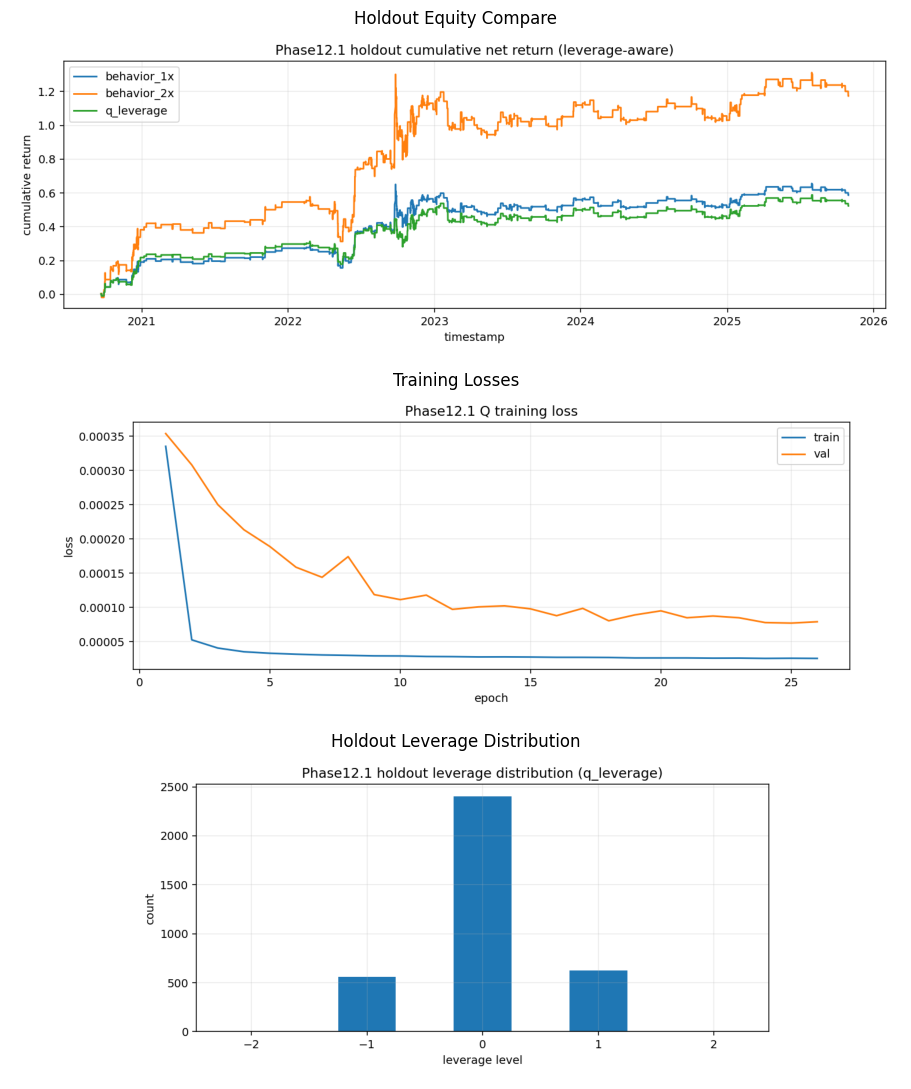

In [5]:
import matplotlib.pyplot as plt

img1 = plt.imread(OUT / 'GBPUSD_phase12_1_holdout_equity_compare.png')
img2 = plt.imread(OUT / 'GBPUSD_phase12_1_training_losses.png')
img3 = plt.imread(OUT / 'GBPUSD_phase12_1_holdout_leverage_hist.png')

fig, ax = plt.subplots(3, 1, figsize=(13, 11))
ax[0].imshow(img1); ax[0].axis('off'); ax[0].set_title('Holdout Equity Compare')
ax[1].imshow(img2); ax[1].axis('off'); ax[1].set_title('Training Losses')
ax[2].imshow(img3); ax[2].axis('off'); ax[2].set_title('Holdout Leverage Distribution')
plt.tight_layout(); plt.show()